In [ ]:
import pandas as pd


In [ ]:
df=pd.read_csv("/content/kyc_alerts_cleaned.csv")

In [ ]:
df.shape

(795, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 795 entries, 0 to 794
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   alert_id              795 non-null    object 
 1   customer_id           795 non-null    object 
 2   customer_type         795 non-null    object 
 3   country               795 non-null    object 
 4   country_risk          780 non-null    object 
 5   customer_risk_rating  795 non-null    object 
 6   alert_type            795 non-null    object 
 7   alert_date            795 non-null    object 
 8   transaction_amount    795 non-null    float64
 9   previous_alerts_90d   795 non-null    int64  
 10  pep_flag              795 non-null    object 
 11  adverse_media_flag    795 non-null    object 
 12  case_status           795 non-null    object 
dtypes: float64(1), int64(1), object(11)
memory usage: 80.9+ KB


In [ ]:
print(df.columns.tolist())

['alert_id', 'customer_id', 'customer_type', 'country', 'country_risk', 'customer_risk_rating', 'alert_type', 'alert_date', 'transaction_amount', 'previous_alerts_90d', 'pep_flag', 'adverse_media_flag', 'case_status']


In [ ]:
df.head

<bound method NDFrame.head of      alert_id customer_id customer_type      country country_risk  \
0    ALT-0001   CUST-0328    Individual      Belarus         High   
1    ALT-0002   CUST-0333     Corporate       Cyprus       Medium   
2    ALT-0003   CUST-0177    Individual         Iran         High   
3    ALT-0004   CUST-0117     Corporate      Germany          Low   
4    ALT-0005   CUST-0088    Individual  Netherlands          Low   
..        ...         ...           ...          ...          ...   
790  ALT-0791   CUST-0014    Individual        Syria         High   
791  ALT-0792   CUST-0112     Corporate       Greece          Low   
792  ALT-0793   CUST-0260     Corporate      Belarus         High   
793  ALT-0794   CUST-0131    Individual       Turkey       Medium   
794  ALT-0795   CUST-0044     Corporate         Iran         High   

    customer_risk_rating                alert_type  alert_date  \
0                 Medium         Large Transaction  2026-02-22   
1                    Low         Unusual Geography  2026-01-04   
2                    Low         Unusual Geography  2026-03-05   
3                 Medium    High-Risk Counterparty  2026-07-14   
4                    Low            Rapid Movement  2026-10-13   
..                   ...                       ...         ...   
790                  Low         Large Transaction  2026-06-28   
791                  Low  Dormant Account Activity  2026-08-14   
792                 High         Large Transaction  2026-04-18   
793                  Low            Rapid Movement  2026-08-04   
794               Medium         Unusual Geography  2026-05-21   

     transaction_amount  previous_alerts_90d pep_flag adverse_media_flag  \
0             110355.30                    0       No                Yes   
1              30587.50                    0       No                 No   
2              24489.87                    1       No                 No   
3               6339.14                    0       No                 No   
4               3255.67                    2      Yes                 No   
..                  ...                  ...      ...                ...   
790            21157.69                    0       No                 No   
791            38861.64                    0       No                 No   
792             5040.18                    1       No                 No   
793             1997.98                    0       No                 No   
794            18716.42                    1      Yes                 No   

      case_status  
0            Open  
1          Closed  
2          Closed  
3    Under Review  
4          Closed  
..            ...  
790  Under Review  
791        Closed  
792          Open  
793        Closed  
794          Open  

[795 rows x 13 columns]>

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
alert_id,0
customer_id,0
customer_type,0
country,0
country_risk,15
customer_risk_rating,0
alert_type,0
alert_date,0
transaction_amount,0
previous_alerts_90d,0


In [ ]:
df["transaction_amount"]=df["transaction_amount"].fillna(df["transaction_amount"].median())

In [ ]:
df["transaction_amount"].isnull().sum()

np.int64(0)

In [ ]:
[col for col in df.columns if "adverse" in col.lower()]

['adverse_media_flag']

In [ ]:
df["adverse_media_flag"]=df["adverse_media_flag"].fillna("Unknown")

In [ ]:
df["adverse_media_flag"].isnull().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
alert_id,0
customer_id,0
customer_type,0
country,0
country_risk,15
customer_risk_rating,0
alert_type,0
alert_date,0
transaction_amount,0
previous_alerts_90d,0


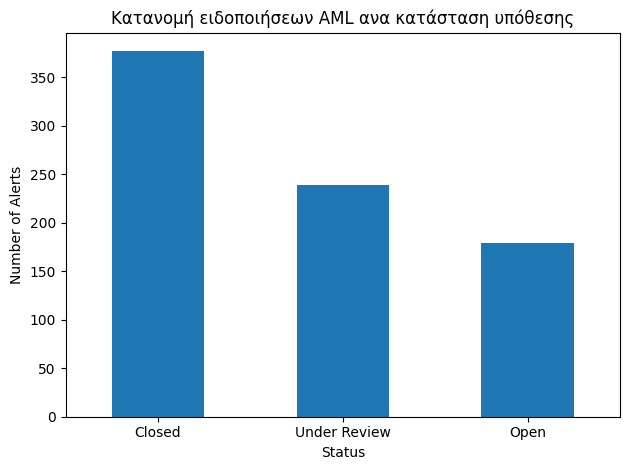

In [ ]:
import matplotlib.pyplot as plt
df["case_status"].value_counts().plot(kind="bar")
plt.title("Κατανομή ειδοποιήσεων AML ανα κατάσταση υπόθεσης")
plt.xlabel("Status")
plt.ylabel("Number of Alerts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

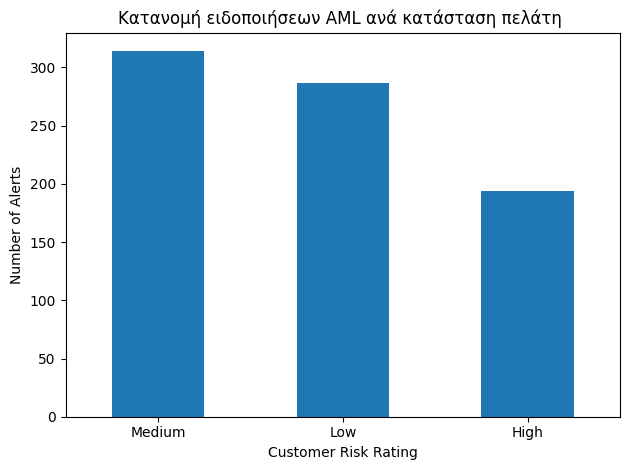

In [ ]:
import matplotlib.pyplot as plt
df["customer_risk_rating"].value_counts().plot(kind="bar")
plt.title("Κατανομή ειδοποιήσεων AML ανά κατάσταση πελάτη ")
plt.xlabel("Customer Risk Rating")
plt.ylabel("Number of Alerts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df["customer_risk_rating"].value_counts()

,count
customer_risk_rating,
Medium,314
Low,287
High,194


In [ ]:
df.loc[df["customer_risk_rating"]=="High","adverse_media_flag"].value_counts()

,count
adverse_media_flag,
No,169
Yes,24
Unknown,1


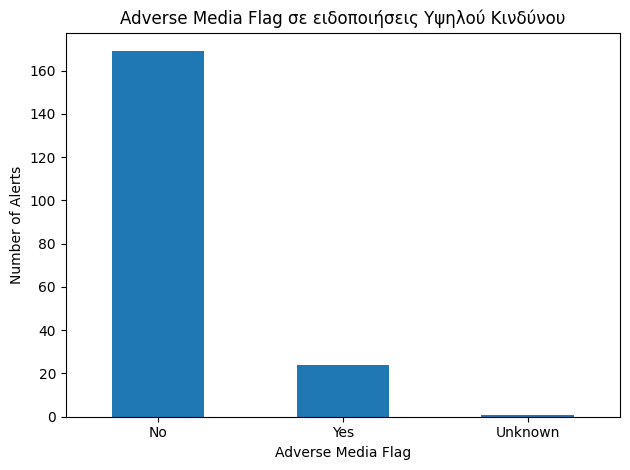

In [ ]:
df.loc[
    df["customer_risk_rating"] == "High",
    "adverse_media_flag"
].value_counts().plot(kind="bar")

plt.title("Adverse Media Flag σε ειδοποιήσεις Υψηλού Κινδύνου")
plt.xlabel("Adverse Media Flag")
plt.ylabel("Number of Alerts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv("kyc_alerts_cleaned.csv",index=False)

In [ ]:
!ls

kyc_alerts_cleaned.csv	sample_data
